# EOS transformation to a table with entropy on axis 1

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import matplotlib.pyplot as pl
import scipy
import scipy.io
import scipy.interpolate
import sys
import os

In [3]:
top='c:/cygwin64/home/codes/dispatch2/'
sys.path.insert(0,top+'utilities/python')

In [4]:
import dispatch
import dispatch.EOS
from dispatch.EOS import deriv,interp,integral

## Any EOS

The ``dispatch.EOS.open()`` method (source code in ``utilities/python/dispatch/EOS/_EOS.py``) knows where to find the data tables, if the ``top`` directory is specified (or -- alternatively -- the environment variable ``DISPATCH`` is set to the top directory):

In [5]:
eos=dispatch.EOS.tomida(top=top,verbose=1)

variables: {0: 'ln(P)', 1: 'ln(E)', 2: 'ln(C_T)', 3: 'ln(cs)', 4: 'gamma', 5: 'ln(Cv)'}


In [6]:
eos=dispatch.EOS.stagger(top=top,verbose=1)

variables: {0: 'ln(P)', 1: 'rkap', 2: 'T', 3: '', 4: 'S1', 5: 'S2', 6: 'S3', 7: 'S4'}


In [7]:
eos=dispatch.EOS.bifrost(top=top,verbose=1)

variables: {0: 'ln(P)', 1: 'T', 2: 'ln(Ne)', 3: 'ln(rkap)'}


Alternative ``open()`` method:

In [8]:
eos=dispatch.EOS.open('bifrost',top=top,verbose=1)

set DISPATCH in the environment to avoid having to set "top=" 
variables: {0: 'ln(P)', 1: 'rkap', 2: 'T', 3: '', 4: 'S1', 5: 'S2', 6: 'S3', 7: 'S4'}


## Conversion to a table based on $(\ln\rho,S)$

#### Tomida & Hori

In [9]:
eosT=dispatch.EOS.tomida(top=top)

Convert to $(\ln\rho,S)$ as independent variables, using the method ``lnT_to_S()``, with source code in ``EOS/tomida.py`` (under ``utilities/python/dispatch/``):

In [10]:
eosTS=eosT.to_S(verbose=2)

type: tomida-S
file: data/eos/tomida/tomida.dat
axis 0: ln(rho)   min=     -50.7 step:     0.115    o:0  n:461 max:       2.3
axis 1: S   min= -1.84e+09 step:  9.27e+06    o:0  n:1000 max:  7.41e+09
variables: {0: 'ln(P)', 1: 'ln(E)', 2: 'ln(C_T)', 3: 'ln(cs)', 4: 'gamma', 5: 'ln(Cv)', 6: 'ln(T)'}


#### Bifrost

In [11]:
eosB=dispatch.EOS.bifrost(top=top,verbose=1)

variables: {0: 'ln(P)', 1: 'T', 2: 'ln(Ne)', 3: 'ln(rkap)'}


Convert to $(\ln\rho,S)$ as independent variables, using the method ``lnT_to_S()``, with source code in ``EOS/tomida.py`` (under ``utilities/python/dispatch/``):

In [12]:
eosBS=eosB.to_S(verbose=2)

type: bifrost-S
file: data/eos/bifrost/eostable.dat
axis 0: ln(rho)   min=     -39.1 step:    0.0692    o:0  n:500 max:     -4.61
axis 1: S   min= -2.03e+09 step:   6.8e+06    o:0  n:1000 max:  4.76e+09
variables: {0: 'ln(P)', 1: 'ln(T)', 2: 'ln(Ne)', 3: 'ln(rkap)', 4: 'ln(E)'}


#### Stagger

In [13]:
eosS=dispatch.EOS.open('stagger',top=top)

Convert to $(\ln\rho,S)$ as independent variables, using the method ``lnT_to_S()``, with source code in ``EOS/tomida.py`` (under ``utilities/python/dispatch/``):

In [14]:
eosSS=eosS.to_S(verbose=2)

type: stagger-E-S
file: data/eos/stagger/48h1/table.dat
axis 0: ln(rho)   min=     -14.4 step:    0.0508    o:0  n:500 max:      11.0
axis 1: S   min= -0.000995 step:  3.56e-06    o:0  n:1000 max:   0.00257
variables: {0: 'ln(P)', 1: 'rkap', 2: 'ln(T)', 3: '', 4: 'S1', 5: 'S2', 6: 'S3', 7: 'S4', 8: 'ln(E)'}


### Illustrations

Show an image of the ``ln(T)`` entry (converted to log10() along with x-axis for plotting) --cf. ``imdhow`` source code in ``EOS/irregular_tables.py``

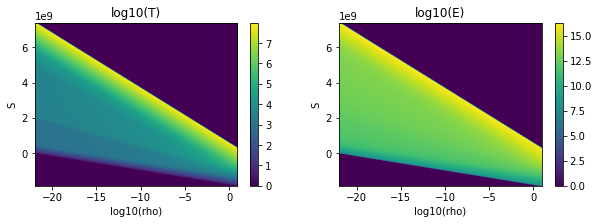

In [15]:
pl.figure(figsize=(10,3))
pl.subplot(1,2,1); eosTS.imshow('ln(T)');
pl.subplot(1,2,2); eosTS.imshow('ln(E)');

Solar model S:

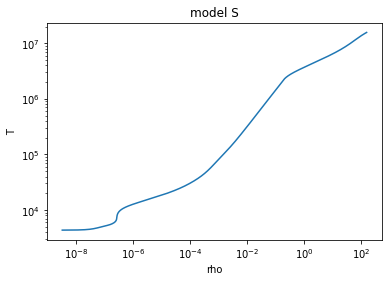

In [16]:
from dispatch.solar_models import JCD_S
model=JCD_S(top=top)
pl.loglog(model.rho,model.T)
pl.xlabel('rho'); pl.ylabel('T'); pl.title('model S');

Reference temperature at rho=1e-5

In [17]:
d_ref=1e-5
Tref=interp(model.rho,model.T,d_ref)
print('{:.1f}'.format(Tref))

18485.9


An adiabat through there extends through essentially the whole table:

In [18]:
def plot_adiabat(eos,d_ref=1e-5):
    ur=eos.info['ur'] if 'ur' in eos.info else 1
    i,p=eos.scale0.index(np.log(d_ref/ur))
    S,lnT=eos.values(i,'ln(T)')
    Sref=interp(lnT,S,np.log(Tref))
    Tadia=[]
    lnd=[]
    for i in range(eos.scale0.n):
        if 'ln(T)' in eos.variables.values():
            S,lnT=eos.values(i,'ln(T)')
        elif 'T' in eos.variables.values():
            S,T=eos.values(i,'ln(T)')
            lnT=np.log(T)
        else:
            lnT,S=eos.values(i,'S')
        if S.min()<Sref and S.max()>Sref:
            Tadia.append(np.exp(dispatch.EOS.interp(S,lnT,Sref)))
            lnd.append(eos.scale0.values[i])
    lnd=np.array(lnd)
    lnd=lnd+np.log(ur)
    Tadia=np.array(Tadia)
    pl.loglog(np.exp(lnd),Tadia,label=eos.file)
    pl.xlabel('rho'); pl.ylabel('T'); pl.title('adiabat, S={:.2}'.format(Sref))
    pl.legend()

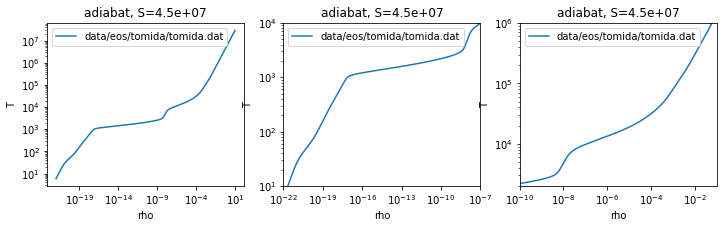

In [19]:
pl.figure(figsize=(12,3))
pl.subplot(1,3,1); plot_adiabat(eosTS)
pl.subplot(1,3,2); plot_adiabat(eosTS); pl.xlim(1e-22,1e-7); pl.ylim(1e1,1e4);
pl.subplot(1,3,3); plot_adiabat(eosTS); pl.xlim(1e-10,1e-1); pl.ylim(2e3,1e6);

In [20]:
def modelS_vs(eos):
    ln10=np.log(10)
    log10d=eos.scale0.values/ln10
    w=np.where(abs(log10d+4) < 4)[0]
    plot_adiabat(eos)
    pl.loglog(model.rho,model.T,color='r',label='Model S')
    pl.xlim(1e-9,2); pl.ylim(3e3,5e6)
    pl.xlabel('rho'); pl.ylabel('T')
    pl.legend();
    pl.title('model adiabat vs. Model S')

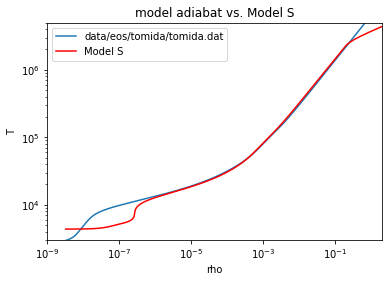

In [21]:
modelS_vs(eosTS)

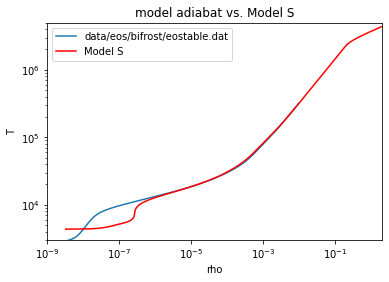

In [22]:
modelS_vs(eosBS)

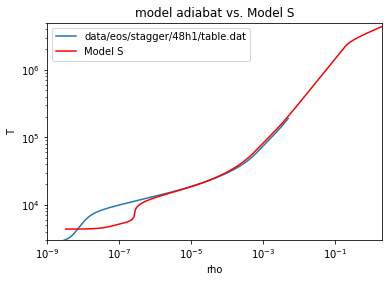

In [23]:
modelS_vs(eosSS)